# 23. Ablasi segmentasi ROI dan normalisasi warna (pooled)
**Penelitian:** Deteksi anemia dari citra pucat (telapak tangan, kuku, konjungtiva) dengan data pooling multi-situs.

**Tujuan:** menguji pengaruh segmentasi ROI (Otsu, K-Means) dan normalisasi warna (White Balance Gray World, CLAHE, kombinasi) pada model pooled LightGBM dengan data bersih. Filter piksel (50<L,R,G<200) dipisahkan dari segmentasi (perlakuan dengan dan tanpa filter) dan pada normalisasi mask dihitung dari hasil normalisasi maupun dari citra asli, sehingga pengaruh masing-masing dapat dibedakan. Seed K-Means ditetapkan. Dilaporkan hasil split tunggal 70:10:20 dan 80:10:10 (uji McNemar eksak terhadap referensi) dan validasi silang berulang 5x5 (rata-rata, SD, selisih berpasangan dengan uji t terkoreksi Nadeau-Bengio), dengan dan tanpa site_id.

**Masukan:** Dataset (Mendeley Data): Palm doi:10.17632/ccr8cm22vz.1, Nail doi:10.17632/2xx4j3kjg2.1, Conjunctiva doi:10.17632/nt7r8hv2pz.1. Letakkan dalam folder `Dataset_Multisite/{Palm,Nail,Conjunctiva}`.

**Keluaran (folder `hasil_revisi`):** `ablasi_split_tunggal.csv`, `ablasi_cv_ringkasan.csv`, `ablasi_cv_perbandingan.csv`, `fitur_ablasi.csv`.

**Kaitan dengan naskah:** Tabel 4 dan 5 (menggantikan Eksperimen 9 dan 10) serta Tabel 9 (validasi silang).

**Cara menjalankan:** Colab, Runtime > Run all. CPU sudah cukup; GPU tidak diperlukan. Seed acak = 42 dan urutan file diurutkan (`sorted`) sehingga hasil dapat direproduksi pada versi pustaka yang dicetak di sel kedua.

In [1]:
!pip install lightgbm -q

In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

Mounted at /content/drive


In [3]:
# ===== FUNGSI BERSAMA (identik di keempat notebook) =====
import os, re, hashlib, warnings
import numpy as np, pandas as pd, cv2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score
from lightgbm import LGBMClassifier
warnings.filterwarnings('ignore')

# ---------- KONFIGURASI (ubah hanya bagian ini) ----------
SEED = 42
BASE = '/content/drive/MyDrive/Dataset_Multisite'   # folder berisi subfolder Palm/, Nail/, Conjunctiva/
OUT  = '/content/drive/MyDrive/hasil_revisi'          # folder keluaran (CSV)
SITES = {'Palm': 0, 'Nail': 1, 'Conjunctiva': 2}
# Filter piksel memeriksa kanal L, R, dan G. Kanal B ikut difilter jika True
# (Appiahene et al. 2023 menuliskan kondisi min < R=G=B < max).
FILTER_INCLUDE_B = False
# True: buang juga citra bernama varian dari citra lain (akhiran FV/RA atau spasi+angka) yang citra dasarnya ada.
BUANG_VARIAN = True
os.makedirs(OUT, exist_ok=True)

# ---------- DAFTAR FILE ----------
def parse_label(name):
    """Label dari awalan nama file (Anemic / Non-Anemic); nama yang mengandung tanda kurung (salinan bernomor) dan awalan tidak dikenali dilewati."""
    if '(' in name: return None
    c = name.lower().replace(' ', '')
    if c.startswith('non-anemic'): return 0
    if c.startswith('anemic'): return 1
    return None

def list_used_files():
    rows = []
    for site, sid in SITES.items():
        d = os.path.join(BASE, site)
        for n in sorted(os.listdir(d)):          # sorted -> urutan deterministik
            lab = parse_label(n)
            if lab is not None:
                rows.append(dict(site=site, site_id=sid, file=n, path=os.path.join(d, n), label=lab))
    return pd.DataFrame(rows)

def md5(path):
    with open(path, 'rb') as f: return hashlib.md5(f.read()).hexdigest()

# ---------- EKSTRAKSI FITUR ----------
def feat_original(img, lo=50, hi=200):
    """Fitur [mean a*, mean b*, mean G] dengan filter piksel. Return (fitur, mask_kosong)."""
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    L, a, b = cv2.split(lab); R, G, B = cv2.split(rgb)
    m = (L > lo) & (L < hi) & (R > lo) & (R < hi) & (G > lo) & (G < hi)
    if FILTER_INCLUDE_B: m &= (B > lo) & (B < hi)
    if m.any(): return [a[m].mean(), b[m].mean(), G[m].mean()], False
    return [0.0, 0.0, 0.0], True

def feat_otsu(img):
    """Fitur dari piksel foreground Otsu (grayscale). Tanpa filter L/R/G. Return (fitur, mask_kosong)."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, mk = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = mk > 0
    if not m.any(): return [0.0, 0.0, 0.0], True
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    _, a, b = cv2.split(lab); G = rgb[:, :, 1]
    return [a[m].mean(), b[m].mean(), G[m].mean()], False

# ---------- PEMBAGIAN DATA & EVALUASI ----------
def split_idx(y, scheme, seed=SEED):
    """Return (train, val, test) berupa indeks. Skema: '80:20', '80:10:10', '70:10:20'."""
    idx = np.arange(len(y))
    if scheme == '80:20':
        tr, te = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
        return tr, None, te
    if scheme == '80:10:10':
        tr, tmp = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
        va, te = train_test_split(tmp, test_size=0.50, stratify=y[tmp], random_state=seed)
        return tr, va, te
    if scheme == '70:10:20':
        trva, te = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
        tr, va = train_test_split(trva, test_size=0.125, stratify=y[trva], random_state=seed)
        return tr, va, te
    raise ValueError(scheme)

def metrics_from(yte, pred, proba):
    tn, fp, fn, tp = confusion_matrix(yte, pred, labels=[0, 1]).ravel()
    assert tn + fp + fn + tp == len(yte), 'TP+TN+FP+FN harus sama dengan jumlah data uji'
    two = len(set(yte)) == 2
    return dict(n_test=len(yte), n_test_anemic=int((yte == 1).sum()), TP=int(tp), TN=int(tn), FP=int(fp), FN=int(fn),
                acc=100*(tp+tn)/len(yte),
                sens=100*tp/(tp+fn) if tp+fn else np.nan,
                spec=100*tn/(tn+fp) if tn+fp else np.nan,
                f1=100*f1_score(yte, pred, zero_division=0),
                auc=100*roc_auc_score(yte, proba) if two else np.nan,
                baseline_mayoritas=100*max((yte == 1).mean(), (yte == 0).mean()))

def fit_lgbm(Xtr, ytr):
    sc = StandardScaler().fit(Xtr)
    m = LGBMClassifier(n_estimators=100, random_state=SEED, verbose=-1).fit(sc.transform(Xtr), ytr)
    return sc, m

def predict_lgbm(sc, m, X):
    proba = m.predict_proba(sc.transform(X))[:, 1]
    return (proba >= 0.5).astype(int), proba

def tandai_dibuang(df):
    """Array boolean (urut baris): True bila baris dibuang pada pembersihan = salinan identik MD5 (satu dipertahankan),
    kedua file pada pasangan identik berlabel berbeda, dan (bila BUANG_VARIAN) citra varian FV/RA. df: indeks 0..n-1 dan kolom md5."""
    konflik = df.groupby('md5').label.transform('nunique') > 1
    dibuang = np.array(df.duplicated('md5', keep='first') | konflik, dtype=bool)   # salinan yang dapat diubah
    if BUANG_VARIAN:
        posisi = np.flatnonzero(~dibuang)
        for a, b in pasangan_varian(df.iloc[posisi].reset_index(drop=True)): dibuang[posisi[a]] = True
    return dibuang

def bersihkan(df):
    """Data bersih untuk semua eksperimen (satu definisi tunggal)."""
    df = df.reset_index(drop=True).copy(); df['md5'] = df['path'].map(md5)
    return df[~tandai_dibuang(df)].reset_index(drop=True)

def cek_kebocoran(md5s, tr, va, te, wajib=True):
    """Pemeriksaan kebocoran: indeks latih/validasi/uji harus saling lepas dan tidak ada citra identik (MD5) lintas partisi.
    Return jumlah citra identik lintas partisi, mis. {'latih-uji': 0}. wajib=True -> hentikan program bila ada pelanggaran."""
    parts = {'latih': set(tr), 'uji': set(te)}
    if va is not None: parts['val'] = set(va)
    nm = sorted(parts)
    for i, a in enumerate(nm):
        for b in nm[i + 1:]:
            assert not (parts[a] & parts[b]), f'Indeks tumpang tindih: {a}-{b}'
    m = {k: set(np.asarray(md5s)[sorted(v)]) for k, v in parts.items()}
    bocor = {f'{a}-{b}': len(m[a] & m[b]) for i, a in enumerate(nm) for b in nm[i + 1:]}
    if wajib: assert all(v == 0 for v in bocor.values()), f'Citra identik lintas partisi: {bocor}'
    return bocor

def pasangan_varian(df):
    """Pasangan (indeks varian, indeks citra dasar) pada df (indeks posisi 0..n-1): nama berakhiran FV/RA atau spasi+angka
    yang nama dasarnya ada pada situs yang sama (mis. Anemic-001FV dengan Anemic-001)."""
    stem = df.file.str.replace(r'\.[A-Za-z]+$', '', regex=True)
    base = stem.str.replace(r'\s\d+$', '', regex=True).str.replace(r'(FV|RA)$', '', regex=True)
    key = {(s, t): i for i, (s, t) in enumerate(zip(df.site, stem))}
    return [(i, key[(s, b)]) for i, (s, t, b) in enumerate(zip(df.site, stem, base)) if b != t and (s, b) in key]

def cek_varian(pasangan, tr, va, te):
    """Jumlah pasangan varian-dasar yang terpisah di partisi berbeda (informasi; idealnya 0)."""
    part = {}
    for ids, nm in [(tr, 'latih'), (va, 'val'), (te, 'uji')]:
        if ids is not None:
            for i in ids: part[i] = nm
    return sum(1 for a, b in pasangan if a in part and b in part and part[a] != part[b])

In [4]:
import sys, numpy, pandas, cv2, sklearn, lightgbm
print('Python', sys.version.split()[0], '| numpy', numpy.__version__, '| pandas', pandas.__version__,
      '| OpenCV', cv2.__version__, '| scikit-learn', sklearn.__version__, '| LightGBM', lightgbm.__version__, '| SEED', SEED)

Python 3.13.16 | numpy 2.4.6 | pandas 2.2.3 | OpenCV 4.14.0 | scikit-learn 1.6.1 | LightGBM 4.6.0 | SEED 42


In [5]:
# ===== ABLASI SEGMENTASI ROI DAN NORMALISASI WARNA (menggantikan Eksperimen 9 dan 10) =====
# Data bersih, split sama dengan notebook lain, seed K-Means tetap, filter piksel dipisahkan dari segmentasi,
# hasil split tunggal (dengan uji McNemar) dan validasi silang berulang (rata-rata, SD, uji t terkoreksi Nadeau-Bengio).
from scipy import stats
from sklearn.model_selection import RepeatedStratifiedKFold

SITE_ID_OPSI = [True, False]          # fitur site_id pada model pooled: dengan (seperti laporan) dan tanpa
N_SPLITS, N_REPEATS = 5, 5            # validasi silang berulang
LO, HI = 50, 200                      # ambang filter piksel (skala 8-bit OpenCV), ditetapkan penulis
REFERENSI = 'Tanpa segmentasi + filter (Original)'

# ---------- data bersih ----------
df = bersihkan(list_used_files())
assert df.md5.is_unique and not pasangan_varian(df), 'Data belum bersih'
y = df.label.to_numpy(); site = df.site_id.to_numpy(float)
print('Data bersih:', len(df), df.groupby('site').label.agg(total='count', anemic='sum').to_dict('index'))

# ---------- fungsi dasar ----------
def lab_rgb(img):
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB); return cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB), rgb
def pix_filter(lab, rgb):
    L, R, G, B = lab[..., 0], rgb[..., 0], rgb[..., 1], rgb[..., 2]
    m = (L > LO) & (L < HI) & (R > LO) & (R < HI) & (G > LO) & (G < HI)
    return m & (B > LO) & (B < HI) if FILTER_INCLUDE_B else m
def fitur(lab, rgb, m):
    if not m.any(): return [0.0, 0.0, 0.0], True
    return [lab[..., 1][m].mean(), lab[..., 2][m].mean(), rgb[..., 1][m].mean()], False

_c = {}                               # cache per citra (dikosongkan untuk tiap citra)
def mask_otsu(img):
    if 'otsu' not in _c:
        _, mk = cv2.threshold(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU); _c['otsu'] = mk > 0
    return _c['otsu']
def mask_kmeans(img):
    if 'km' not in _c:
        Z = img.reshape((-1, 3)).astype(np.float32); cv2.setRNGSeed(SEED)          # seed tetap -> deterministik
        crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)
        _, lb, ct = cv2.kmeans(Z, 2, None, crit, 10, cv2.KMEANS_RANDOM_CENTERS)
        _c['km'] = (lb.flatten() == np.argmax(ct.sum(axis=1))).reshape(img.shape[:2])   # klaster paling terang
    return _c['km']

def apply_white_balance(img):         # Gray World
    b, g, r = [c.astype(np.float32) for c in cv2.split(img)]
    mu = [max(c.mean(), 1e-6) for c in (b, g, r)]; gray = sum(mu) / 3
    return cv2.merge([np.clip(c * (gray / m), 0, 255).astype(np.uint8) for c, m in zip((b, g, r), mu)])
def apply_clahe(img):                 # CLAHE pada kanal L, clipLimit=2,0, tile 8x8
    l, a, b = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2LAB))
    l = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)
    return cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2BGR)
def apply_wb_clahe(img): return apply_clahe(apply_white_balance(img))
def norm(img, kind):
    if kind not in _c: _c[kind] = {'wb': apply_white_balance, 'clahe': apply_clahe, 'wbc': apply_wb_clahe}[kind](img)
    return _c[kind]

def arm_seg(maskfn, use_filter):
    def f(img):
        lab, rgb = lab_rgb(img)
        m = np.ones(lab.shape[:2], bool) if maskfn is None else maskfn(img)
        return fitur(lab, rgb, (m & pix_filter(lab, rgb)) if use_filter else m)
    return f
def arm_color(kind, mask_asli):
    def f(img):
        lab, rgb = lab_rgb(norm(img, kind))
        if mask_asli: lab0, rgb0 = lab_rgb(img); return fitur(lab, rgb, pix_filter(lab0, rgb0))
        return fitur(lab, rgb, pix_filter(lab, rgb))
    return f

ARMS = {  # nama: (kelompok, fungsi)
    'Tanpa segmentasi, tanpa filter': ('segmentasi', arm_seg(None, False)),
    REFERENSI: ('segmentasi+normalisasi', arm_seg(None, True)),
    'Otsu': ('segmentasi', arm_seg(mask_otsu, False)),
    'Otsu + filter': ('segmentasi', arm_seg(mask_otsu, True)),
    'K-Means': ('segmentasi', arm_seg(mask_kmeans, False)),
    'K-Means + filter': ('segmentasi', arm_seg(mask_kmeans, True)),
    'White Balance (mask dari hasil)': ('normalisasi', arm_color('wb', False)),
    'CLAHE (mask dari hasil)': ('normalisasi', arm_color('clahe', False)),
    'WB+CLAHE (mask dari hasil)': ('normalisasi', arm_color('wbc', False)),
    'White Balance (mask citra asli)': ('normalisasi', arm_color('wb', True)),
    'CLAHE (mask citra asli)': ('normalisasi', arm_color('clahe', True)),
    'WB+CLAHE (mask citra asli)': ('normalisasi', arm_color('wbc', True))}

# ---------- ekstraksi fitur sekali (cache) ----------
FT = {k: [] for k in ARMS}; KOSONG = {k: 0 for k in ARMS}
for p in df.path:
    _c.clear(); img = cv2.imread(p)
    for k, (_, fn) in ARMS.items():
        f, e = fn(img); FT[k].append(f); KOSONG[k] += int(e)
FT = {k: np.array(v) for k, v in FT.items()}
print('Citra dengan mask kosong (fitur diisi 0):', {k: v for k, v in KOSONG.items() if v})
pd.concat([df[['site', 'file', 'label']]] + [pd.DataFrame(v, columns=[f'{k}|a', f'{k}|b', f'{k}|G']) for k, v in FT.items()], axis=1).to_csv(os.path.join(OUT, 'fitur_ablasi.csv'), index=False)

def X_of(k, ws): return np.column_stack([FT[k], site]) if ws else FT[k]

# ---------- (1) split tunggal ----------
def mcnemar_exact(yt, p_ref, p_arm):
    b = int(((p_ref == yt) & (p_arm != yt)).sum()); c = int(((p_ref != yt) & (p_arm == yt)).sum())
    return 1.0 if b + c == 0 else float(stats.binomtest(min(b, c), b + c, 0.5).pvalue)

rows = []
for scheme in ['70:10:20', '80:10:10']:
    tr, va, te = split_idx(y, scheme)
    print(f'\nSkema {scheme}: kebocoran', cek_kebocoran(df.md5.to_numpy(), tr, va, te), '| uji =', len(te))
    for ws in SITE_ID_OPSI:
        P = {}
        for k, (grup, _) in ARMS.items():
            X = X_of(k, ws); sc, m = fit_lgbm(X[tr], y[tr]); pr, pb = predict_lgbm(sc, m, X[te]); P[k] = pr
            rows.append(dict(skema=scheme, site_id='dengan' if ws else 'tanpa', kelompok=grup, perlakuan=k, **metrics_from(y[te], pr, pb)))
        for r in rows[-len(ARMS):]: r['mcnemar_p_vs_referensi'] = round(mcnemar_exact(y[te], P[REFERENSI], P[r['perlakuan']]), 4)
split_df = pd.DataFrame(rows).round(2); split_df.to_csv(os.path.join(OUT, 'ablasi_split_tunggal.csv'), index=False)
print(split_df[split_df.site_id == 'dengan'][['skema', 'perlakuan', 'n_test', 'TP', 'TN', 'FP', 'FN', 'acc', 'sens', 'spec', 'f1', 'auc', 'mcnemar_p_vs_referensi']].to_string(index=False))

# ---------- (2) validasi silang berulang ----------
strat = (site * 2 + y).astype(int)       # stratifikasi gabungan situs x label
folds = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED).split(np.zeros(len(y)), strat))
rasio = float(np.mean([len(te) / len(tr) for tr, te in folds]))
M = ['acc', 'auc', 'f1', 'sens', 'spec']
SK = {}
for ws in SITE_ID_OPSI:
    for k in ARMS:
        X = X_of(k, ws); hasil = {m: [] for m in M}
        for tr, te in folds:
            sc, mdl = fit_lgbm(X[tr], y[tr]); pr, pb = predict_lgbm(sc, mdl, X[te]); r = metrics_from(y[te], pr, pb)
            for m in M: hasil[m].append(r[m])
        SK[(ws, k)] = {m: np.array(v) for m, v in hasil.items()}
ringkas = []
for (ws, k), v in SK.items():
    ringkas.append(dict(site_id='dengan' if ws else 'tanpa', kelompok=ARMS[k][0], perlakuan=k, **{f'{m}_mean': v[m].mean() for m in M}, **{f'{m}_sd': v[m].std(ddof=1) for m in M}))
ringkas = pd.DataFrame(ringkas).round(2); ringkas.to_csv(os.path.join(OUT, 'ablasi_cv_ringkasan.csv'), index=False)

def banding(d):                          # uji t terkoreksi (Nadeau-Bengio) untuk selisih berpasangan antar-lipatan
    k = len(d); m = d.mean(); v = d.var(ddof=1)
    if v < 1e-12: return m, np.nan, np.nan, np.nan            # selisih konstan (mis. fitur identik): uji tidak terdefinisi
    se = np.sqrt((1 / k + rasio) * v)
    h = stats.t.ppf(0.975, k - 1) * se
    return m, m - h, m + h, 2 * stats.t.sf(abs(m / se), k - 1)
bd = []
for (ws, k), v in SK.items():
    if k == REFERENSI: continue
    for m in ['auc', 'acc']:
        mu, lo, hi, p = banding(v[m] - SK[(ws, REFERENSI)][m])
        bd.append(dict(site_id='dengan' if ws else 'tanpa', perlakuan=k, metrik=m, selisih_vs_referensi=mu, ci95_bawah=lo, ci95_atas=hi, p_nadeau_bengio=p))
bd = pd.DataFrame(bd)
# Holm adjustment for the 11 AUC contrasts reported in manuscript Table V (with site_id).
# p_nadeau_bengio is the Nadeau-Bengio corrected paired-test p-value, not Holm-adjusted.
bd['p_holm_11_kontras_auc'] = np.nan
m_auc = (bd.site_id == 'dengan') & (bd.metrik == 'auc')
p_raw = bd.loc[m_auc, 'p_nadeau_bengio'].astype(float).to_numpy()
assert len(p_raw) == 11, f'Diharapkan 11 kontras AUC untuk Holm, ditemukan {len(p_raw)}'
urutan = np.argsort(p_raw)
p_sorted = p_raw[urutan]
p_adj_sorted = np.maximum.accumulate((len(p_raw) - np.arange(len(p_raw))) * p_sorted)
p_adj_sorted = np.minimum(p_adj_sorted, 1.0)
p_adj = np.empty_like(p_raw)
p_adj[urutan] = p_adj_sorted
bd.loc[m_auc, 'p_holm_11_kontras_auc'] = p_adj
bd = bd.round(4)
bd.to_csv(os.path.join(OUT, 'ablasi_cv_perbandingan.csv'), index=False)
print(f'\n=== Validasi silang {N_SPLITS}x{N_REPEATS} (rata-rata ± SD), referensi = {REFERENSI} ===')
t = ringkas[ringkas.site_id == 'dengan']
print(t[['perlakuan', 'acc_mean', 'acc_sd', 'auc_mean', 'auc_sd', 'sens_mean', 'spec_mean']].to_string(index=False))
print('\n=== Selisih vs referensi (AUC, dengan site_id), uji t terkoreksi ===')
print(bd[(bd.site_id == 'dengan') & (bd.metrik == 'auc')][['perlakuan', 'selisih_vs_referensi', 'ci95_bawah', 'ci95_atas', 'p_nadeau_bengio']].to_string(index=False))

Data bersih: 1345 {'Conjunctiva': {'total': 514, 'anemic': 291}, 'Nail': {'total': 312, 'anemic': 293}, 'Palm': {'total': 519, 'anemic': 301}}
Citra dengan mask kosong (fitur diisi 0): {'Tanpa segmentasi + filter (Original)': 38, 'Otsu + filter': 130, 'K-Means + filter': 122, 'White Balance (mask dari hasil)': 4, 'CLAHE (mask dari hasil)': 62, 'WB+CLAHE (mask dari hasil)': 28, 'White Balance (mask citra asli)': 38, 'CLAHE (mask citra asli)': 38, 'WB+CLAHE (mask citra asli)': 38}

Skema 70:10:20: kebocoran {'latih-uji': 0, 'latih-val': 0, 'uji-val': 0} | uji = 269

Skema 80:10:10: kebocoran {'latih-uji': 0, 'latih-val': 0, 'uji-val': 0} | uji = 135
   skema                            perlakuan  n_test  TP  TN  FP  FN   acc  sens  spec    f1   auc  mcnemar_p_vs_referensi
70:10:20       Tanpa segmentasi, tanpa filter     269 142  52  40  35 72.12 80.23 56.52 79.11 77.08                    0.81
70:10:20 Tanpa segmentasi + filter (Original)     269 148  49  43  29 73.23 83.62 53.26 80.43 76

In [6]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
OUT = '/content/drive/MyDrive/hasil_revisi'          # folder berisi CSV hasil
LABEL = ['Non-anemic', 'Anemic']

def cm_dari_baris(r):
    """Matriks [[TN, FP], [FN, TP]]: baris = kelas sebenarnya, kolom = prediksi."""
    cm = np.array([[r['TN'], r['FP']], [r['FN'], r['TP']]], dtype=int)
    n = r['n_test'] if 'n_test' in r.index else r['n']
    assert cm.sum() == n, f'TP+TN+FP+FN ({cm.sum()}) harus sama dengan jumlah data ({n})'
    return cm

def gambar_cm(cm, judul, ax):
    pct = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None) * 100      # persen per kelas sebenarnya
    ax.imshow(pct, cmap='Blues', vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]}\n({pct[i, j]:.1f}%)', ha='center', va='center', fontsize=9,
                    color='white' if pct[i, j] > 50 else 'black')
    ax.set_xticks([0, 1]); ax.set_xticklabels(LABEL, fontsize=8); ax.set_yticks([0, 1]); ax.set_yticklabels(LABEL, fontsize=8)
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Sebenarnya'); ax.set_title(judul, fontsize=8)

def grid_cm(df, judul, ncol=4, simpan=None, judul_utama=''):
    n = len(df); nrow = int(np.ceil(n / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(3.3 * ncol, 3.4 * nrow), squeeze=False)
    for ax in axs.ravel(): ax.axis('off')
    for ax, (_, r) in zip(axs.ravel(), df.iterrows()):
        ax.axis('on'); gambar_cm(cm_dari_baris(r), judul(r), ax)
    fig.suptitle(judul_utama); plt.tight_layout()
    if simpan: plt.savefig(os.path.join(OUT, simpan), dpi=150)
    plt.show()

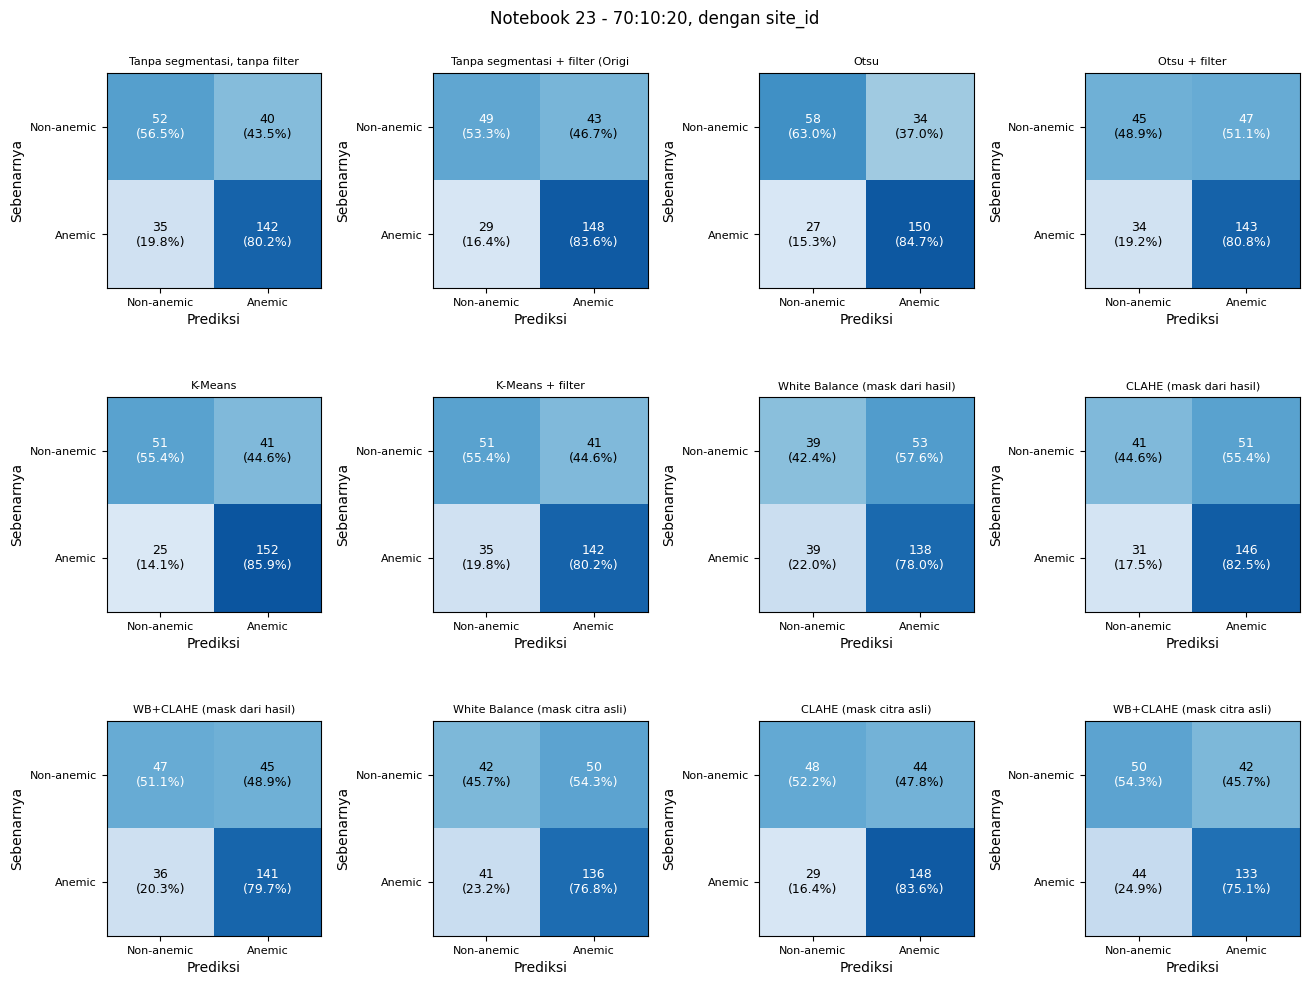

In [7]:
a = pd.read_csv(f'{OUT}/ablasi_split_tunggal.csv')
d = a[(a.site_id == 'dengan') & (a.skema == '70:10:20')]                       # site_id: 'dengan' atau 'tanpa'
grid_cm(d, lambda r: r['perlakuan'][:32], ncol=4, simpan='cm_nb23.png', judul_utama='Notebook 23 - 70:10:20, dengan site_id')